# CSCI461 Assignment 1 — Dockerized SMS Spam Analysis
**Approved dataset:** UCI SMS Spam Collection  
**Task:** end-to-end EDA, text analysis, supervised classification, K-Means and persistent output generation.

Run **Kernel → Restart Kernel and Run All Cells** inside the supplied Docker container. Interpretations below are computed from the actual data, not fabricated.

In [1]:

from pathlib import Path
import re
import warnings
from collections import Counter
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer

# Classification Models
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB

# Clustering
from sklearn.cluster import MiniBatchKMeans

# Evaluation Metrics
from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    silhouette_score,
    adjusted_rand_score
)


ROOT = Path.cwd()

if ROOT.name == "notebook":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "dataset.csv"
OUTPUT = ROOT / "output"
FIG = OUTPUT / "figures"

OUTPUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

assert DATA.exists(), f"Missing dataset: {DATA}"

sns.set_theme(style="whitegrid")
SEED = 42

print("Running from:", ROOT)
print("Dataset exists:", DATA.exists())
print("All libraries imported successfully!")

Running from: /home/jovyan/bd-a1
Dataset exists: True
All libraries imported successfully!


In [2]:
from pathlib import Path

ROOT = Path.cwd()

if ROOT.name == "notebook":
    ROOT = ROOT.parent

DATA = ROOT / "data" / "dataset.csv"
OUTPUT = ROOT / "output"
FIG = OUTPUT / "figures"

OUTPUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)

print("Project folder:", ROOT)
print("Dataset path:", DATA)
print("Dataset exists:", DATA.exists())

assert DATA.exists(), f"Missing dataset: {DATA}"

Project folder: /home/jovyan/bd-a1
Dataset path: /home/jovyan/bd-a1/data/dataset.csv
Dataset exists: True


## 1. Dataset understanding

In [3]:
df = pd.read_csv(DATA, encoding='utf-8')
assert {'label','text'}.issubset(df.columns), 'Expected columns label and text'
print('First five rows:'); display(df.head())
print('Shape:',df.shape,'Columns:',list(df.columns))
print('Data types:'); display(df.dtypes)
df.info()
print('Descriptive statistics:'); display(df.describe(include='all'))
print('One row = one SMS message. text = unstructured text; label = ham/spam category. Numeric features will be engineered.')

First five rows:


,label,text
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


Shape: (5572, 2) Columns: ['label', 'text']
Data types:


label    object
text     object
dtype: object

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5572 entries, 0 to 5571
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   label   5572 non-null   object
 1   text    5572 non-null   object
dtypes: object(2)
memory usage: 87.2+ KB
Descriptive statistics:


,label,text
count,5572,5572
unique,2,5169
top,ham,"Sorry, I'll call later"
freq,4825,30


One row = one SMS message. text = unstructured text; label = ham/spam category. Numeric features will be engineered.


## 2. Missing data, duplicates and three transformations

In [4]:
print('Nulls before:',df.isna().sum().to_dict())
print('Full duplicate rows before:',int(df.duplicated().sum()))
before=df.shape
# Missing text cannot support text modeling; missing labels cannot be targets.
df = df.dropna(subset=['label','text']).copy()
df['label'] = df['label'].astype(str).str.strip().str.lower()
df = df[df['label'].isin(['ham','spam'])].copy()
df['text'] = df['text'].astype(str)
df = df[df['text'].str.strip().ne('')].drop_duplicates(subset=['label','text']).reset_index(drop=True)
# Transformation 1: numeric target encoding
df['is_spam'] = (df['label']=='spam').astype('int8')
# Transformation 2: text/size-derived numeric features
df['char_count'] = df['text'].str.len()
df['word_count'] = df['text'].str.split().str.len()
# Transformation 3: useful binning
df['length_band'] = pd.cut(df['char_count'], bins=[-1,50,120,np.inf], labels=['short','medium','long'])
# Transformation 4: normalized length (z-score)
sd = df['char_count'].std()
df['length_zscore'] = (df['char_count'] - df['char_count'].mean()) / (sd if sd else 1)
print('Before:',before,'After:',df.shape)
print('Nulls after:',df.isna().sum().to_dict(),'Duplicates after:',df.duplicated(subset=['label','text']).sum())
print('Rationale: Remove unusable missing text/labels and exact duplicate message-label pairs to avoid training/test leakage. Retain raw text.')
display(df.head())

Nulls before: {'label': 0, 'text': 0}
Full duplicate rows before: 403
Before: (5572, 2) After: (5169, 7)
Nulls after: {'label': 0, 'text': 0, 'is_spam': 0, 'char_count': 0, 'word_count': 0, 'length_band': 0, 'length_zscore': 0} Duplicates after: 0
Rationale: Remove unusable missing text/labels and exact duplicate message-label pairs to avoid training/test leakage. Retain raw text.


,label,text,is_spam,char_count,word_count,length_band,length_zscore
0,ham,"Go until jurong point, crazy.. Available only ...",0,111,20,medium,0.538916
1,ham,Ok lar... Joking wif u oni...,0,29,6,short,-0.862629
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1,155,28,long,1.290964
3,ham,U dun say so early hor... U c already then say...,0,49,11,short,-0.520789
4,ham,"Nah I don't think he goes to usf, he lives aro...",0,61,13,medium,-0.315685


## 3. loc, iloc and np.r_

In [5]:
print('Conditional loc: spam messages longer than 120 characters')
display(df.loc[(df['label']=='spam') & (df['char_count']>120), ['label','text','char_count']].head())
print('Positional iloc:'); display(df.iloc[:5,:3])
print('np.r_ iloc: first 3 and last 3 rows'); display(df.iloc[np.r_[0:3, len(df)-3:len(df)], :3])

Conditional loc: spam messages longer than 120 characters


,label,text,char_count
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,155
5,spam,FreeMsg Hey there darling it's been 3 week's n...,148
8,spam,WINNER!! As a valued network customer you have...,158
9,spam,Had your mobile 11 months or more? U R entitle...,154
11,spam,"SIX chances to win CASH! From 100 to 20,000 po...",136


Positional iloc:


,label,text,is_spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0


np.r_ iloc: first 3 and last 3 rows


,label,text,is_spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
5166,ham,"Pity, * was in mood for that. So...any other s...",0
5167,ham,The guy did some bitching but I acted like i'd...,0
5168,ham,Rofl. Its true to its name,0


## 4. Random, stratified and cluster sampling

In [6]:
sample_n = min(500,len(df))
random_sample=df.sample(n=sample_n,random_state=SEED)
# Stratified sampling preserves the ham/spam ratios, unlike a simple random sample.
strat_parts=[]
for label, group in df.groupby('label'):
    count=max(1,round(sample_n*len(group)/len(df)))
    strat_parts.append(group.sample(n=min(count,len(group)),random_state=SEED))
strat_sample=pd.concat(strat_parts)
# For SMS without natural source identifiers, length_band is an explicitly explained surrogate cluster.
# This tests a real cluster/whole-group selection, not random rows named 'cluster sampling'.
rng=np.random.default_rng(SEED)
all_groups=df['length_band'].dropna().astype(str).unique()
selected_groups=rng.choice(all_groups,size=max(1,min(2,len(all_groups))),replace=False)
cluster_sample=df[df['length_band'].astype(str).isin(selected_groups)]
comparisons=[]
for name,s in [('Original',df),('Simple random',random_sample),('Stratified',strat_sample),('Cluster (length bands)',cluster_sample)]:
    proportions=s['label'].value_counts(normalize=True)
    comparisons.append({'method':name,'n':len(s),'ham_%':round(100*proportions.get('ham',0),2),'spam_%':round(100*proportions.get('spam',0),2)})
display(pd.DataFrame(comparisons))
print('Sampled length-band clusters:',selected_groups.tolist())
print('Simple random: every record has a chance; stratified: preserves class proportions; cluster: selects whole length bands, so proportions can shift. Length-band clusters are an illustrative proxy because the dataset lacks natural source group IDs.')

,method,n,ham_%,spam_%
0,Original,5169,87.37,12.63
1,Simple random,500,87.80,12.20
2,Stratified,500,87.40,12.60
3,Cluster (length bands),2996,78.87,21.13


Sampled length-band clusters: ['medium', 'long']
Simple random: every record has a chance; stratified: preserves class proportions; cluster: selects whole length bands, so proportions can shift. Length-band clusters are an illustrative proxy because the dataset lacks natural source group IDs.


## 5. Correlation of numeric text features

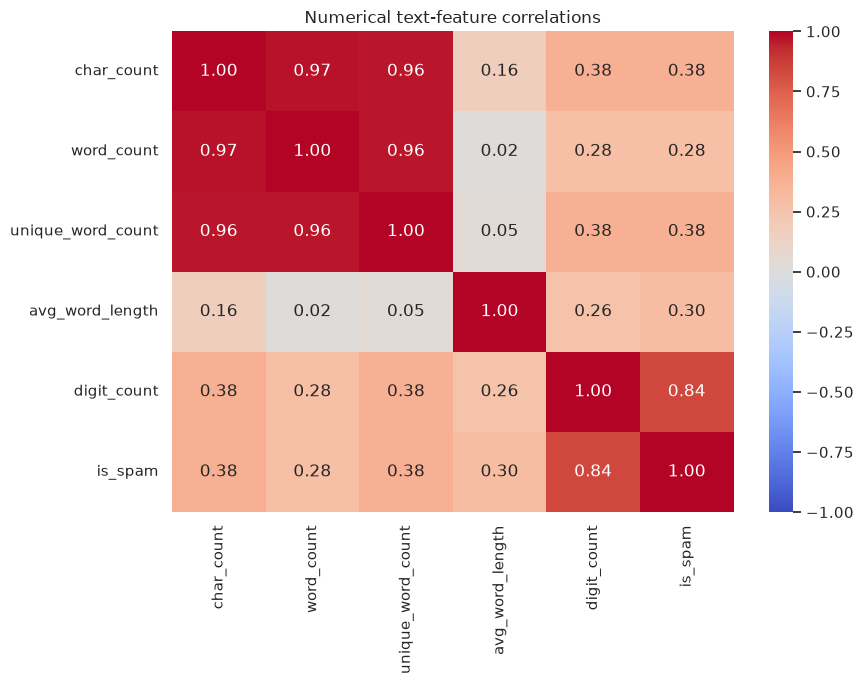

Strongest pair: ('char_count', 'word_count'), r=0.974. Weakest: ('word_count', 'avg_word_length'), r=0.023.
Correlation is association only; shared dependence on message length and other confounders means correlation does not establish causality.


In [7]:
def words(s): return re.findall(r"\b\w+\b",str(s).lower())
df['unique_word_count']=df['text'].map(lambda s:len(set(words(s))))
df['avg_word_length']=df['text'].map(lambda s: float(np.mean([len(w) for w in words(s)])) if words(s) else 0)
df['digit_count']=df['text'].str.count(r'\d')
features=['char_count','word_count','unique_word_count','avg_word_length','digit_count','is_spam']
corr=df[features].corr(numeric_only=True)
plt.figure(figsize=(9,7)); sns.heatmap(corr,annot=True,fmt='.2f',cmap='coolwarm',vmin=-1,vmax=1)
plt.title('Numerical text-feature correlations');plt.tight_layout();plt.savefig(FIG/'01_correlation_heatmap.png',dpi=160);plt.show()
pairs=corr.where(np.triu(np.ones(corr.shape),1).astype(bool)).stack()
strong=pairs.abs().idxmax(); weak=pairs.abs().idxmin()
print(f'Strongest pair: {strong}, r={pairs.loc[strong]:.3f}. Weakest: {weak}, r={pairs.loc[weak]:.3f}.')
print('Correlation is association only; shared dependence on message length and other confounders means correlation does not establish causality.')

## 6. Text cleaning and frequency analysis

Total tokens: 79986 Unique: 7740 Avg words/record: 15.47


,word,frequency
0,i,2860
1,you,2150
2,to,2080
3,a,1325
4,the,1249
5,u,1090
6,and,930
7,in,835
8,is,800
9,me,758


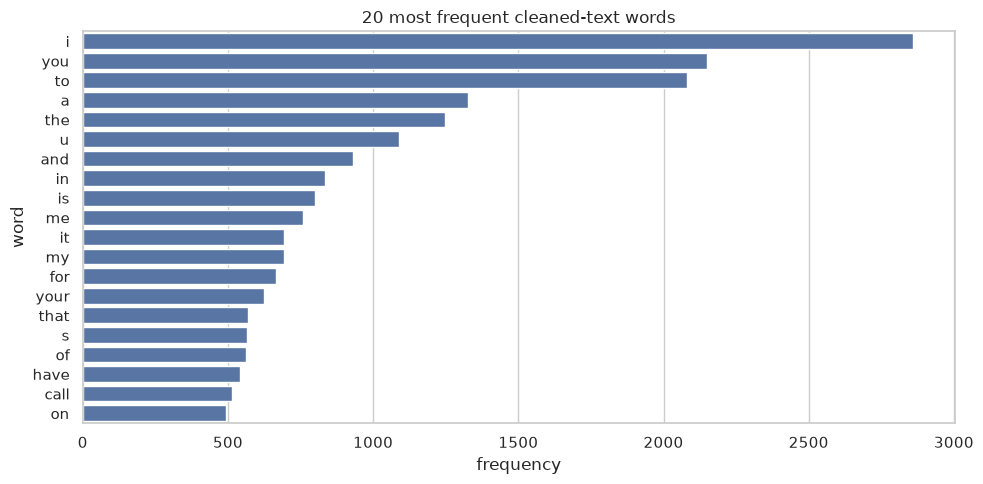

Top 20 without stop words:


,word,frequency
0,u,1090
1,s,565
2,t,468
3,m,440
4,just,350
5,ur,322
6,gt,288
7,lt,287
8,ok,261
9,free,253


In [8]:
def clean_text(value):
    if pd.isna(value): return ''
    s=str(value).lower()
    s=re.sub(r'https?://\S+|www\.\S+', ' URL ',s)
    s=re.sub(r'\b\d+\b',' NUM ',s)
    s=re.sub(r'[^a-z\s]',' ',s)
    return re.sub(r'\s+',' ',s).strip()
df['cleaned_text']=df['text'].map(clean_text)
df['tokens']=df['cleaned_text'].str.split()
all_tokens=[t for record in df['tokens'] for t in record]
print('Total tokens:',len(all_tokens),'Unique:',len(set(all_tokens)),'Avg words/record:',round(len(all_tokens)/len(df),2))
counts=Counter(all_tokens)
top20=pd.DataFrame(counts.most_common(20),columns=['word','frequency'])
display(top20)
fig,ax=plt.subplots(figsize=(10,5));sns.barplot(data=top20,x='frequency',y='word',ax=ax)
ax.set_title('20 most frequent cleaned-text words');plt.tight_layout();plt.savefig(FIG/'02_top_words.png',dpi=160);plt.show()
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
no_stop=Counter(t for t in all_tokens if t not in ENGLISH_STOP_WORDS)
print('Top 20 without stop words:');display(pd.DataFrame(no_stop.most_common(20),columns=['word','frequency']))

## 7. Group comparison and five evidence-based insights

,n,avg_char_count,avg_word_count
label,,,
ham,4516,70.99,14.24
spam,653,138.13,23.74


Top 10 non-stop words for ham: [('u', 938), ('s', 481), ('m', 397), ('t', 388), ('gt', 288), ('lt', 287), ('just', 282), ('ok', 256), ('ll', 233), ('got', 228)]
Top 10 non-stop words for spam: [('free', 197), ('p', 158), ('u', 152), ('txt', 138), ('ur', 119), ('stop', 116), ('mobile', 111), ('text', 108), ('claim', 96), ('reply', 96)]


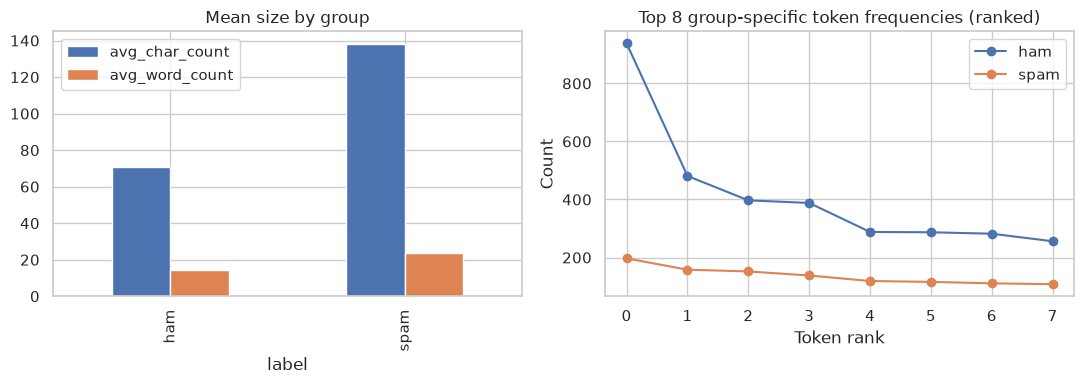

FIVE DATA-GROUNDED INSIGHTS
1) Observation: spam is 12.6% of usable records. Evidence: 653 / 5169. Interpretation: majority-class accuracy is misleading.
2) Observation: spam averages 138.1 chars vs ham 71.0. Evidence: group means. Interpretation: length may be predictive, but need not be causal.
3) Observation: 7,740 distinct tokens over 79,986 total. Evidence: vocabulary/total ratio=0.097. Interpretation: a sparse vectorizer fits this setting.
4) Observation: most frequent word is "i" (2860 occurrences). Evidence: word frequency table. Interpretation: stop-word removal can reveal more topic-specific words.
5/6) Observation: highest-frequency non-stop word in ham is "u" (938 uses). Evidence: class-specific token count. Interpretation: word choice differs by class but must be evaluated using held-out data.
5/6) Observation: highest-frequency non-stop word in spam is "free" (197 uses). Evidence: class-specific token count. Interpretation: word choice differs by class but must be evaluat

In [9]:
group_summary=df.groupby('label').agg(n=('text','size'),avg_char_count=('char_count','mean'),avg_word_count=('word_count','mean')).round(2)
display(group_summary)
group_counters={lab:Counter(t for tokens in group['tokens'] for t in tokens if t not in ENGLISH_STOP_WORDS) for lab,group in df.groupby('label')}
for lab,ct in group_counters.items():
    print(f'Top 10 non-stop words for {lab}:',ct.most_common(10))
fig,axes=plt.subplots(1,2,figsize=(11,4))
group_summary[['avg_char_count','avg_word_count']].plot(kind='bar',ax=axes[0],title='Mean size by group')
for lab in ['ham','spam']:
    top=group_counters[lab].most_common(8)
    axes[1].plot([v for k,v in top],label=lab,marker='o')
axes[1].set_title('Top 8 group-specific token frequencies (ranked)');axes[1].set_xlabel('Token rank');axes[1].set_ylabel('Count');axes[1].legend()
plt.tight_layout();plt.savefig(FIG/'03_group_comparison.png',dpi=160);plt.show()
spam_rate=100*df['is_spam'].mean()
long_pct=df.groupby('label')['char_count'].mean()
uniq_ratio=len(set(all_tokens))/max(1,len(all_tokens))
common=counts.most_common(1)[0]
print('FIVE DATA-GROUNDED INSIGHTS')
print(f'1) Observation: spam is {spam_rate:.1f}% of usable records. Evidence: {df.is_spam.sum()} / {len(df)}. Interpretation: majority-class accuracy is misleading.')
print(f'2) Observation: spam averages {long_pct.get("spam",0):.1f} chars vs ham {long_pct.get("ham",0):.1f}. Evidence: group means. Interpretation: length may be predictive, but need not be causal.')
print(f'3) Observation: {len(set(all_tokens)):,} distinct tokens over {len(all_tokens):,} total. Evidence: vocabulary/total ratio={uniq_ratio:.3f}. Interpretation: a sparse vectorizer fits this setting.')
print(f'4) Observation: most frequent word is "{common[0]}" ({common[1]} occurrences). Evidence: word frequency table. Interpretation: stop-word removal can reveal more topic-specific words.')
for lab in ['ham','spam']:
    print(f'5/6) Observation: highest-frequency non-stop word in {lab} is "{group_counters[lab].most_common(1)[0][0]}" ({group_counters[lab].most_common(1)[0][1]} uses). Evidence: class-specific token count. Interpretation: word choice differs by class but must be evaluated using held-out data.')

## 8. TF-IDF supervised classification (bonus: comparison of two classifiers)

LogisticRegression               precision    recall  f1-score   support

         ham       0.99      0.98      0.99       903
        spam       0.88      0.92      0.90       131

    accuracy                           0.97      1034
   macro avg       0.94      0.95      0.94      1034
weighted avg       0.98      0.97      0.98      1034

MultinomialNB               precision    recall  f1-score   support

         ham       0.96      1.00      0.98       903
        spam       1.00      0.71      0.83       131

    accuracy                           0.96      1034
   macro avg       0.98      0.85      0.90      1034
weighted avg       0.96      0.96      0.96      1034



,accuracy,macro_precision,macro_recall,macro_f1
LogisticRegression,0.9749,0.9360,0.953,0.9443
MultinomialNB,0.9632,0.9798,0.855,0.9049


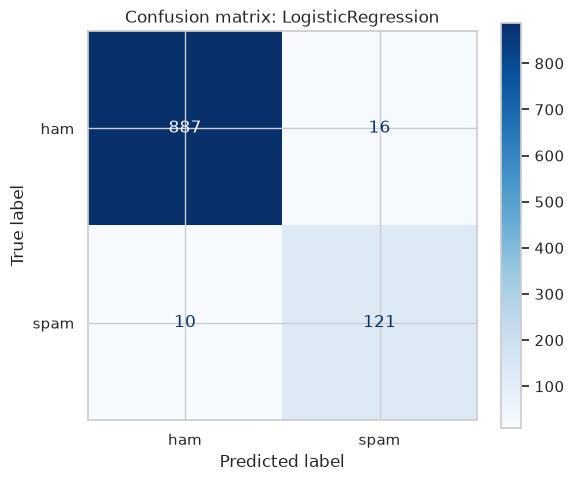

Supervised model comparison (held-out 20% test split, stratified, seed=42)
LogisticRegression: accuracy=0.9749, macro_precision=0.9360, macro_recall=0.9530, macro_f1=0.9443
MultinomialNB: accuracy=0.9632, macro_precision=0.9798, macro_recall=0.8550, macro_f1=0.9049
Selected model: LogisticRegression (highest macro-F1)

Classification report:
              precision    recall  f1-score   support

         ham       0.99      0.98      0.99       903
        spam       0.88      0.92      0.90       131

    accuracy                           0.97      1034
   macro avg       0.94      0.95      0.94      1034
weighted avg       0.98      0.97      0.98      1034

Limitation: historic English SMS may not generalize to newer languages, campaigns or drift. Also, text preprocessing removes some spam-specific punctuation.



In [10]:
X_train, X_test, y_train, y_test = train_test_split(df['cleaned_text'], df['label'], test_size=.2, random_state=SEED, stratify=df['label'])
vectorizer=TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=12000,sublinear_tf=True)
Xt=vectorizer.fit_transform(X_train); Xv=vectorizer.transform(X_test)
models={'LogisticRegression':LogisticRegression(max_iter=2000,class_weight='balanced',random_state=SEED), 'MultinomialNB':MultinomialNB()}
results={}; predictions={}
for name,model in models.items():
    model.fit(Xt,y_train);yp=model.predict(Xv);predictions[name]=yp
    precision,recall,f1,_=precision_recall_fscore_support(y_test,yp,average='macro',zero_division=0)
    results[name]={'accuracy':accuracy_score(y_test,yp),'macro_precision':precision,'macro_recall':recall,'macro_f1':f1}
    print(name,classification_report(y_test,yp,zero_division=0))
display(pd.DataFrame(results).T.round(4))
best=max(results,key=lambda key:results[key]['macro_f1']); pred=predictions[best]
fig,ax=plt.subplots(figsize=(6,5));ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=['ham','spam'],cmap='Blues',ax=ax)
ax.set_title('Confusion matrix: '+best);plt.tight_layout();plt.savefig(FIG/'04_confusion_matrix.png',dpi=160);plt.show()
metrics_text='Supervised model comparison (held-out 20% test split, stratified, seed=42)\n'+'\n'.join(f'{name}: '+', '.join(f'{k}={v:.4f}' for k,v in values.items()) for name,values in results.items())
metrics_text+=f'\nSelected model: {best} (highest macro-F1)\n\nClassification report:\n'+classification_report(y_test,pred,zero_division=0)
metrics_text+='\nLimitation: historic English SMS may not generalize to newer languages, campaigns or drift. Also, text preprocessing removes some spam-specific punctuation.\n'
(OUTPUT/'model_metrics.txt').write_text(metrics_text,encoding='utf-8')
print(metrics_text)

## 9. Unsupervised K-Means text clustering

In [11]:
# Unsupervised fit: classes are NOT passed to K-Means.
# k=2 is defensible as an exploratory hypothesis because there are two known broad label categories,
# but clusters are themes, not guaranteed spam/ham predictions.
cluster_vec=TfidfVectorizer(max_features=2500,min_df=3,max_df=.95,stop_words='english')
Z=cluster_vec.fit_transform(df['cleaned_text'])
k=2
km=MiniBatchKMeans(n_clusters=k,random_state=SEED,n_init=10,batch_size=256)
ids=km.fit_predict(Z)
cluster_sizes=pd.Series(ids).value_counts().sort_index()
# sample avoids expensive full pairwise distance computation
sample_size=min(800,len(df)); subset=np.random.default_rng(SEED).choice(len(df),sample_size,replace=False)
if len(set(ids[subset]))>1:
    sil=silhouette_score(Z[subset],ids[subset],metric='cosine')
else:
    sil=float('nan')
terms=cluster_vec.get_feature_names_out(); top_indices=km.cluster_centers_.argsort(axis=1)[:,::-1]
cluster_desc=[]
for i in range(k):
    top=', '.join(terms[j] for j in top_indices[i,:12]); desc=f'Cluster {i}: {cluster_sizes.get(i,0)} messages; prominent terms: {top}'
    print(desc);cluster_desc.append(desc)
compare=pd.crosstab(pd.Series(ids,name='cluster'),df['label'],normalize='index').round(3)
display(compare)
ari=adjusted_rand_score(df['label'],ids)
summary='K-Means / MiniBatchKMeans over TF-IDF; k=2 (exploratory two-category hypothesis)\n'+ '\n'.join(cluster_desc)
summary+=f'\nCosine silhouette on deterministic sample of {sample_size}: {sil:.4f}\nAdjusted Rand index vs known labels: {ari:.4f}\n'
summary+='\nKnown-label proportions within each unsupervised cluster:\n'+compare.to_string()
summary+='\nInterpretation: cluster topics inferred from top terms, not predefined class names. Cluster IDs need not equal class IDs. Weak alignment or low silhouette indicates heterogeneous SMS themes.\n'
(OUTPUT/'cluster_summary.txt').write_text(summary,encoding='utf-8');print(summary)

Cluster 0: 122 messages; prominent terms: claim, prize, urgent, won, cash, ppm, guaranteed, award, holiday, selected, receive, box
Cluster 1: 5047 messages; prominent terms: ok, like, gt, lt, come, just, ll, good, know, free, ur, going


label,ham,spam
cluster,,
0,0.000,1.000
1,0.895,0.105


K-Means / MiniBatchKMeans over TF-IDF; k=2 (exploratory two-category hypothesis)
Cluster 0: 122 messages; prominent terms: claim, prize, urgent, won, cash, ppm, guaranteed, award, holiday, selected, receive, box
Cluster 1: 5047 messages; prominent terms: ok, like, gt, lt, come, just, ll, good, know, free, ur, going
Cosine silhouette on deterministic sample of 800: 0.0069
Adjusted Rand index vs known labels: 0.2521

Known-label proportions within each unsupervised cluster:
label      ham   spam
cluster              
0        0.000  1.000
1        0.895  0.105
Interpretation: cluster topics inferred from top terms, not predefined class names. Cluster IDs need not equal class IDs. Weak alignment or low silhouette indicates heterogeneous SMS themes.



## 10. Save all persistent artifacts and verify

In [12]:
# Lists of tokens are kept for analysis but serialized as strings only when necessary.
df.drop(columns=['tokens']).to_csv(OUTPUT/'cleaned_data.csv',index=False)
required=['cleaned_data.csv','model_metrics.txt','cluster_summary.txt']
for filename in required: assert (OUTPUT/filename).exists(),filename
figs=sorted(FIG.glob('*.png')); assert len(figs)>=4
print('Outputs:');print('\n'.join(str(x.relative_to(ROOT)) for x in sorted(OUTPUT.rglob('*')) if x.is_file()))
print('SUCCESS: all required notebook-generated artifacts exist.')

Outputs:
output/cleaned_data.csv
output/cluster_summary.txt
output/figures/01_correlation_heatmap.png
output/figures/02_top_words.png
output/figures/03_group_comparison.png
output/figures/04_confusion_matrix.png
output/model_metrics.txt
SUCCESS: all required notebook-generated artifacts exist.
